# Book Recommendation Tool

This notebook contains the steps I used to prepare the data and build the files for the ReadWell Staff Console. I start with the Goodreads data and then prepare the books, train and test the sentiment models, and create the recommendation method.

The final files are saved in the `Book_Rec_Final` folder in Google Drive. I also save the main results in `thesis_numbers.json` so I can use the same numbers in my thesis.

## Part A - Setup

In [ ]:

# Mount Google Drive to save the prepared files and results.
from google.colab import drive
drive.mount('/content/drive')

import os, re, json, csv, gc, time, html, subprocess, inspect, sys, platform, hashlib
import numpy as np
import pandas as pd
import joblib

RUN_STARTED = time.time()

# Save all prepared files and results in this folder.
OUT_DIR = '/content/drive/MyDrive/Book_Rec_Final'
# Large raw files are kept in Colab storage because they take up a lot of space.
RAW_DIR = '/content/raw'
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(RAW_DIR, exist_ok=True)

# All the choices that were made are mentioned here
DATASET         = 'pypiahmad/goodreads-book-reviews1'   # used the publig Goodreads dataset from Kaggle
TARGET_GENRES   = ['romance', 'fantasy', 'mystery']     # Only these three genres were kept
MIN_SHELF_COUNT = 50          # a genre shelf only counts if at least 50 users used it
MIN_TAG_COUNT   = 3           # a shelf must be used by at least 3 users to be a similarity tag
MAX_SIM_TAGS    = 30          # at most 30 tags per book are used for similarity(strongest tags will be kept)
REVIEW_SAMPLE   = 200_000     # number of reviews used to train and test the sentiment models
TEST_SIZE       = 0.2         # 20% of those reviews are kept aside for testing
RANDOM_SEED     = 42          # this makes every random step repeatable
MIN_REVIEWS     = 10          # reviews needed before a book gets a reception label
MIN_RATINGS     = 25_000      # "popular books" = at least this many Goodreads ratings; these books go into the app

# Save the main results in one JSON file for the thesis.
RESULTS_PATH = f'{OUT_DIR}/thesis_numbers.json'
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}

def _plain(o):
    return o.item() if hasattr(o, 'item') else str(o)

def record(key, value):
    RESULTS[key] = value
    with open(RESULTS_PATH, 'w') as f:
        json.dump(RESULTS, f, indent=2, default=_plain)
    shown = value if not isinstance(value, (dict, list)) else '(saved)'
    print(f'  recorded {key}: {shown}')

import sklearn
record('library_versions', {'python': platform.python_version(), 'scikit-learn': sklearn.__version__,
                            'pandas': pd.__version__, 'numpy': np.__version__})
print('Output folder:', OUT_DIR)

Mounted at /content/drive
  recorded library_versions: (saved)
Output folder: /content/drive/MyDrive/Book_Rec_Final


In [ ]:
# Install the Kaggle downloader
!pip install -q kaggle

In this part, I set up the notebook and download the Goodreads files from Kaggle. I download the book, author and review data again so the notebook can start with the original files. I also check the files before moving on to the next steps.

In [ ]:
# Kaggle login, download, unzip, and checks (Output is removed to hide the username)
try:
    from google.colab import userdata
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print('Kaggle details read from Colab Secrets')
except Exception:
    from getpass import getpass
    os.environ['KAGGLE_USERNAME'] = input('Kaggle username: ')
    os.environ['KAGGLE_KEY'] = getpass('Kaggle key (hidden): ')

def download_file(name):
    path = f'{RAW_DIR}/{name}'
    if os.path.exists(path):
        print(name, 'is already on disk')
        return path
    print('Downloading', name, '(10-30 minutes for the big ones) ...')
    subprocess.run(['kaggle', 'datasets', 'download', '-d', DATASET, '-f', name, '-p', RAW_DIR], check=True)
    zip_path = path + '.zip'
    if os.path.exists(zip_path):
        subprocess.run(['unzip', '-q', '-o', zip_path, '-d', RAW_DIR], check=True)
        os.remove(zip_path)
    assert os.path.exists(path), f'{name} was not found after the download'
    return path

def check_file(path, min_lines):
    n = int(subprocess.check_output(['wc', '-l', path]).split()[0])
    tail = subprocess.check_output(['tail', '-c', '300', path]).decode('utf-8', 'replace').strip()
    size_gb = os.path.getsize(path) / 1024**3
    print(f'{os.path.basename(path)}: {n:,} lines, {size_gb:.2f} GB, ends with ...{tail[-50:]!r}')
    assert n >= min_lines, f'{path} has only {n:,} lines - it is incomplete. Stop and download again.'
    assert tail.endswith('}'), f'{path} ends in the middle of a record - it is cut off. Stop and download again.'
    return n

BOOKS_PATH   = f'{RAW_DIR}/goodreads_books.json'
AUTHORS_PATH = f'{RAW_DIR}/goodreads_book_authors.json'
REVIEWS_PATH = f'{RAW_DIR}/goodreads_reviews_dedup.json'

# A raw file is downloaded only if a later step still needs it.
# the big files are gone from Colab's disk, but everything made from them is saved on Drive, so nothing is downloaded again.
need_books   = not os.path.exists(f'{OUT_DIR}/books_df.pkl')
need_authors = not os.path.exists(f'{OUT_DIR}/author_names.json')
need_reviews = not (os.path.exists(f'{OUT_DIR}/filtered_reviews.csv') and os.path.exists(f'{OUT_DIR}/book_sentiment.csv'))
print('Raw files needed in this run -> books:', need_books, '| authors:', need_authors, '| reviews:', need_reviews)

raw_lines = RESULTS.get('raw_file_lines', {})
if need_books:
    BOOKS_PATH = download_file('goodreads_books.json');  raw_lines['books'] = check_file(BOOKS_PATH, 2_300_000)
if need_authors:
    AUTHORS_PATH = download_file('goodreads_book_authors.json');  raw_lines['authors'] = check_file(AUTHORS_PATH, 500_000)
if need_reviews:
    REVIEWS_PATH = download_file('goodreads_reviews_dedup.json');  raw_lines['reviews'] = check_file(REVIEWS_PATH, 15_000_000)
record('raw_file_lines', raw_lines)

## Part B - Choose the books and clean their tags

In this part, I select the books for the recommendation tool and prepare their information. I check the language and descriptions, and organise the books into the three genres used in the app. I also clean the reader-generated tags by removing unrelated tags, such as personal and book-format tags. The books are checked for duplicates using their work IDs.

In [ ]:
# Books table
OLD_NOISE = {'to-read', 'currently-reading', 'owned', 'favorites', 'books-i-own',
             'default', 'kindle', 'ebook', 'library', 'wish-list', 'abandoned'}

NOISE_EXACT = OLD_NOISE | {'owned-books', 'own', 'my-books', 'favourites', 'favorite', 'read', 'reading', 'tbr',
                           'to-buy', 'wishlist', 'dnf', 'did-not-finish', 'audiobook', 'audiobooks', 'audio',
                           'e-book', 'ebooks', 'books', 'book', 'paperback', 'hardcover', 'physical', 'borrowed',
                           'purchased', 'bought', 'received', 'netgalley', 'arc', 'goodreads', 'giveaways', 'gift',
                           'series', 'finished', 're-read', 'reread', 'recommended', 'calibre', 'ya-fiction-to-read'}

NOISE_RE = re.compile(
    r'(^|-)(19|20)\d\d($|-)'                                                   # years: 2014-reads, read-in-2015
    r'|(^|-)(to-)?(read|reads|reading|buy|get|own|owned|reread|re-read|tbr|dnf)($|-)'
    r'|favou?rite|kindle|e-?book|audio|netgalley|goodreads|library|wish-?list|currently|abandon|unfinished'
    r'|owned|^my-|-shelf$|^shelf|book-?club|giveaway|purchased|bought|borrowed|gift|^arc($|-)'
    r'|(^|-)series($|-)|stand-?alones?|(^|-)(maybe|have|want|wanted|nook|audible|kobo|ibooks|hoopla|overdrive|libby|reviewed|novels?|on-hold)($|-)'
    r'|\d\s*-?\s*stars?|^\d+(\.\d+)?$|rating|ebooks?-')

def useful_tag(name, count):
    # True if a shelf tells us something about the story (not about the reader or the format)
    return (count >= MIN_TAG_COUNT and len(name) >= 3 and name not in NOISE_EXACT and not NOISE_RE.search(name))

def build_books_table(path):
    best = {}      # work_id -> row; only the most-rated edition of each work is kept
    matched_total = 0
    with open(path, 'rt', encoding='utf-8') as f:
        for i, line in enumerate(f):
            if i % 200_000 == 0:
                print(f'Processed {i:,} lines, matched {matched_total:,}, distinct works {len(best):,}')
            book = json.loads(line)
            if not book.get('description'):
                continue
            lang = book.get('language_code', '')
            if lang and not lang.startswith('en'):
                continue
            shelves = book.get('popular_shelves', [])
            if not [s for s in shelves if s['name'].lower() in TARGET_GENRES and int(s.get('count', 0)) >= MIN_SHELF_COUNT]:
                continue
            matched_total += 1
            work_id = str(book.get('work_id'))
            ratings = int(book.get('ratings_count', 0) or 0)
            if work_id in best and best[work_id]['ratings_count'] >= ratings:
                continue
            pairs = [(s['name'].lower(), int(s.get('count', 0))) for s in shelves]
            sim = sorted([(n, c) for n, c in pairs if useful_tag(n, c)], key=lambda x: -x[1])[:MAX_SIM_TAGS]
            authors = book.get('authors') or []
            best[work_id] = {
                'book_id': str(book.get('book_id')),
                'work_id': work_id,
                'title': book.get('title'),
                'description': book.get('description'),
                'ratings_count': ratings,
                'clean_tags_str': ', '.join(s['name'] for s in shelves if s['name'].lower() not in OLD_NOISE),
                'sim_tags': dict(sim),
                'author_id': str(authors[0].get('author_id', '')) if authors else '',
                'series_ids': [str(x) for x in (book.get('series') or [])],
                'similar_books': [str(x) for x in (book.get('similar_books') or [])],
                'isbn13': (book.get('isbn13') or '').strip(),
                'isbn': (book.get('isbn') or '').strip(),
                'image_url': (book.get('image_url') or '').replace('http://', 'https://'),
                'year': book.get('publication_year') or '',
            }
    return i + 1, matched_total, best

BOOKS_PKL = f'{OUT_DIR}/books_df.pkl'
if os.path.exists(BOOKS_PKL):
    books_df = pd.read_pickle(BOOKS_PKL)
    print('Loaded the saved books table:', len(books_df), 'books')
else:
    lines_read, matched_total, best = build_books_table(BOOKS_PATH)
    books_df = pd.DataFrame(sorted(best.values(), key=lambda r: r['work_id'])).reset_index(drop=True)
    books_df.to_pickle(BOOKS_PKL)
    record('books_file_lines_read', lines_read)
    record('books_matching_before_dedup', matched_total)
    record('books_after_dedup', len(books_df))
    del best
    gc.collect()

print(f'{len(books_df):,} books after removing duplicate editions')
for genre in TARGET_GENRES:
    print(genre, books_df['clean_tags_str'].str.lower().str.contains(genre).sum(), 'books mention it in their tags')

Processed 0 lines, matched 0, distinct works 0
Processed 200,000 lines, matched 16,512, distinct works 11,177
Processed 400,000 lines, matched 32,856, distinct works 17,749
Processed 600,000 lines, matched 48,995, distinct works 21,990
Processed 800,000 lines, matched 65,346, distinct works 25,167
Processed 1,000,000 lines, matched 81,532, distinct works 27,379
Processed 1,200,000 lines, matched 97,757, distinct works 29,116
Processed 1,400,000 lines, matched 114,400, distinct works 30,480
Processed 1,600,000 lines, matched 130,889, distinct works 31,509
Processed 1,800,000 lines, matched 147,120, distinct works 32,281
Processed 2,000,000 lines, matched 163,323, distinct works 32,888
Processed 2,200,000 lines, matched 179,640, distinct works 33,355
  recorded books_file_lines_read: 2360655
  recorded books_matching_before_dedup: 192667
  recorded books_after_dedup: 33657
33,657 books after removing duplicate editions
romance 22011 books mention it in their tags
fantasy 17390 books ment

In [ ]:
# Check the tags manually, If any noise tags were found I could add that to the list and rerun the above code
from collections import Counter
tag_counter = Counter()
for d in books_df['sim_tags']:
    tag_counter.update(d.keys())
print('Number of different similarity tags:', len(tag_counter))
print('60 most common similarity tags:')
print(', '.join(f'{t} ({c})' for t, c in tag_counter.most_common(60)))

Number of different similarity tags: 23035
60 most common similarity tags:
fiction (31616), romance (19976), adult (17183), fantasy (16720), contemporary (13941), mystery (13930), young-adult (10647), adventure (8898), magic (8705), paranormal (8517), contemporary-romance (7654), mysteries (7430), suspense (7340), crime (7230), historical-fiction (6964), sci-fi-fantasy (6945), historical (6875), chick-lit (6870), mystery-thriller (6706), supernatural (6659), adult-fiction (6651), thriller (6326), urban-fantasy (6111), mystery-suspense (5814), science-fiction (5580), sci-fi (5395), teen (4780), humor (4607), fantasy-sci-fi (4544), paranormal-romance (4543), erotica (4310), new-adult (3793), action (3618), detective (3574), funny (3573), alpha-male (3551), ya-fiction (3447), high-fantasy (3412), ya-fantasy (3396), scifi-fantasy (3389), england (3356), historical-romance (3355), horror (3163), drama (3084), family (2833), childrens (2818), mystery-crime (2758), romance-contemporary (2741)

## Part C - The lightweight sentiment model (Naive Bayes)

In this part, I prepare the reviews and train the lightweight sentiment model. I use star ratings to group reviews into positive, neutral and negative classes. I take the first 200,000 matching reviews from the review file because working with the full dataset would require more memory. I split the sample into training and test sets and compare the model with and without class weights.

In [ ]:
# Prepare the review sample, create labels, split the data and train the model
book_ids = set(books_df['book_id'].astype(str))

# Check each review against the book IDs in the selected books
def filter_reviews_streaming(path, book_ids, output_path, max_reviews):
    kept = 0
    with open(path, 'rt', encoding='utf-8') as f_in, open(output_path, 'w', newline='', encoding='utf-8') as f_out:
        writer = csv.DictWriter(f_out, fieldnames=['book_id', 'review_text', 'rating'])
        writer.writeheader()
        for i, line in enumerate(f_in):
            if kept >= max_reviews:
                break
            if i % 200_000 == 0:
                print(f'Processed {i:,} lines, kept {kept:,} reviews so far...')
            review = json.loads(line)
            rid = str(review.get('book_id'))
            if rid in book_ids:
                writer.writerow({'book_id': rid, 'review_text': review.get('review_text'), 'rating': review.get('rating')})
                kept += 1
    return kept, i + 1

# Make the review sample (the first 200,000 matching reviews), or reuse the saved one.
sample_csv = f'{OUT_DIR}/filtered_reviews.csv'
if os.path.exists(sample_csv):
    print('Using the saved review sample (the same 200,000 reviews as before)')
else:
    kept, lines_used = filter_reviews_streaming(REVIEWS_PATH, book_ids, sample_csv, REVIEW_SAMPLE)
    print(f'{kept:,} reviews kept after reading {lines_used:,} lines of the reviews file')
    record('review_sample_lines_read', lines_used)

# Load the sample and check how many books it covers
reviews_df = pd.read_csv(sample_csv, dtype={'book_id': str})
print('Books with at least one sampled review:', reviews_df['book_id'].nunique(), 'of', len(books_df))
record('review_sample_books_covered', int(reviews_df['book_id'].nunique()))

# Drop reviews without text
reviews_df = reviews_df.dropna(subset=['review_text']).copy()
print('Reviews with text:', len(reviews_df))
record('review_sample_with_text', len(reviews_df))

# Assign sentiment labels based on star ratings
def rating_to_sentiment(r):
    if r >= 4: return 'positive'
    elif r <= 2: return 'negative'
    return 'neutral'

reviews_df['sentiment'] = reviews_df['rating'].apply(rating_to_sentiment)
print(reviews_df['sentiment'].value_counts(normalize=True).round(3).to_dict())
record('sample_class_share', reviews_df['sentiment'].value_counts(normalize=True).round(4).to_dict())

Processed 0 lines, kept 0 reviews so far...
Processed 200,000 lines, kept 68,185 reviews so far...
Processed 400,000 lines, kept 138,704 reviews so far...
200,000 reviews kept after reading 581,963 lines of the reviews file
  recorded review_sample_lines_read: 581963
Books with at least one sampled review: 25427 of 33657
  recorded review_sample_books_covered: 25427
Reviews with text: 199866
  recorded review_sample_with_text: 199866
{'positive': 0.683, 'neutral': 0.192, 'negative': 0.125}
  recorded sample_class_share: (saved)


#### Training the lightweight model

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_sample_weight

# Split the data 80/20
X_train, X_test, y_train, y_test = train_test_split(
    reviews_df['review_text'], reviews_df['sentiment'], test_size=TEST_SIZE, random_state=RANDOM_SEED)
print(f'Training reviews: {len(X_train):,}    Test reviews: {len(X_test):,}')
record('train_reviews', len(X_train))
record('test_reviews', len(X_test))

# turn text into numbers using TF-IDF
review_vectorizer = TfidfVectorizer(stop_words='english', max_features=5000)
X_train_vec = review_vectorizer.fit_transform(X_train)     # the vocabulary is learned from the training reviews only
X_test_vec = review_vectorizer.transform(X_test)

# first version: no weights
model_unweighted = MultinomialNB().fit(X_train_vec, y_train)
pred_unweighted = model_unweighted.predict(X_test_vec)
print('--- BEFORE class weighting ---')
print(classification_report(y_test, pred_unweighted))

# final version: rare classes count more
sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)
sentiment_model = MultinomialNB().fit(X_train_vec, y_train, sample_weight=sample_weights)
lightweight_predictions = sentiment_model.predict(X_test_vec)
print('--- AFTER class weighting (final model) ---')
print(classification_report(y_test, lightweight_predictions))

record('unweighted_report', classification_report(y_test, pred_unweighted, output_dict=True))
record('lightweight_report', classification_report(y_test, lightweight_predictions, output_dict=True))

joblib.dump(sentiment_model, f'{OUT_DIR}/sentiment_model.joblib')       # the trained model
joblib.dump(review_vectorizer, f'{OUT_DIR}/review_vectorizer.joblib')   # the word-to-number converter
# the test reviews and their labels
X_test.to_csv(f'{OUT_DIR}/X_test.csv', index=False)
y_test.to_csv(f'{OUT_DIR}/y_test.csv', index=False)

Training reviews: 159,892    Test reviews: 39,974
  recorded train_reviews: 159892
  recorded test_reviews: 39974
--- BEFORE class weighting ---
              precision    recall  f1-score   support

    negative       0.83      0.16      0.27      5052
     neutral       0.50      0.06      0.11      7703
    positive       0.71      0.99      0.83     27219

    accuracy                           0.71     39974
   macro avg       0.68      0.41      0.40     39974
weighted avg       0.69      0.71      0.62     39974

--- AFTER class weighting (final model) ---
              precision    recall  f1-score   support

    negative       0.42      0.62      0.50      5052
     neutral       0.36      0.54      0.43      7703
    positive       0.88      0.68      0.77     27219

    accuracy                           0.64     39974
   macro avg       0.55      0.61      0.57     39974
weighted avg       0.72      0.64      0.67     39974

  recorded unweighted_report: (saved)
  recorded 

## Part D - A reception label for every book

In this part, I use the trained model to predict the sentiment of the reviews. I calculate the share of positive, neutral and negative reviews for each book. I then use these results to give each book a reception label. Books with fewer than 10 reviews are marked as not having enough reviews. I also save progress during processing so I do not lose all the results if something goes wrong.

In [ ]:
# score every review
import pickle
from collections import defaultdict

SENT_CSV = f'{OUT_DIR}/book_sentiment.csv'
if os.path.exists(SENT_CSV):
    book_sent = pd.read_csv(SENT_CSV, dtype={'book_id': str})
    print('Loaded the saved labels:', len(book_sent), 'books')
else:
    # progress is saved in a checkpoint file in case Colab disconnects.
    ckpt_path = f'{OUT_DIR}/sent_checkpoint.pkl'
    counts = defaultdict(lambda: [0, 0, 0, 0])          # total, positive, negative, neutral
    start_line, bad_lines = 0, 0

    # If a checkpoint exists, continue from the saved line instead of starting again
    if os.path.exists(ckpt_path):
        saved = pickle.load(open(ckpt_path, 'rb'))
        counts.update(saved['counts'])
        start_line, bad_lines = saved['next_line'], saved['bad_lines']
        print(f'Resuming from line {start_line:,}')

    batch_ids, batch_texts = [], []
    BATCH = 50_000

    def flush():
        if not batch_texts:
            return
        preds = sentiment_model.predict(review_vectorizer.transform(batch_texts))
        for bid, p in zip(batch_ids, preds):
            c = counts[bid]
            c[0] += 1
            if p == 'positive': c[1] += 1
            elif p == 'negative': c[2] += 1
            else: c[3] += 1
        batch_ids.clear(); batch_texts.clear()

    def save_checkpoint(next_line):
        flush()
        with open(ckpt_path, 'wb') as f:
            pickle.dump({'counts': dict(counts), 'next_line': next_line, 'bad_lines': bad_lines}, f)

    # Read the whole reviews file line by line
    last_line = start_line
    with open(REVIEWS_PATH, 'rt', encoding='utf-8', errors='replace') as f:
        for i, line in enumerate(f):
            last_line = i
            if i < start_line:
                continue

            # Save a checkpoint every 1,000,000 lines
            if i % 1_000_000 == 0 and i > start_line:
                save_checkpoint(i)
                print(f'Processed {i:,} lines, books with reviews so far: {len(counts):,}')
            try:
                r = json.loads(line)
            except json.JSONDecodeError:
                bad_lines += 1            # if the line is unreadable then it is skipped
                continue
            bid = str(r.get('book_id'))
            text = r.get('review_text')

            # Keep only reviews of my books that have text, and score them in batches
            if bid in book_ids and text:
                batch_ids.append(bid); batch_texts.append(text)
                if len(batch_texts) >= BATCH:
                    flush()
    save_checkpoint(last_line + 1)
    print(f'Done. Lines read: {last_line + 1:,}, unreadable lines skipped: {bad_lines}')
    record('scan_lines_read', last_line + 1)
    record('scan_unreadable_lines', bad_lines)

    # One row per book: number of reviews, and the share of positive and negative in %
    book_sent = pd.DataFrame([(b, c[0], c[1] / c[0] * 100, c[2] / c[0] * 100) for b, c in counts.items()],
                             columns=['book_id', 'n_reviews', 'pos_pct', 'neg_pct'])

    # Rank only the books with at least 10 reviews, by their positive share (0 = lowest, 1 = highest)
    enough = book_sent['n_reviews'] >= MIN_REVIEWS
    book_sent['rank_pct'] = np.nan
    book_sent.loc[enough, 'rank_pct'] = book_sent.loc[enough, 'pos_pct'].rank(pct=True)

    # Bottom 25% = Weaker, middle 50% = Typical, top 25% = Strong
    book_sent['tier'] = pd.cut(book_sent['rank_pct'], bins=[0, 0.25, 0.75, 1.0],
                               labels=['Weaker reception', 'Typical reception', 'Strong reception'])
    book_sent['tier'] = book_sent['tier'].astype(str).replace('nan', 'Not enough reviews')
    book_sent.to_csv(SENT_CSV, index=False)
    if os.path.exists(ckpt_path):
        os.remove(ckpt_path)

print('Books with reviews:', len(book_sent), ' with at least', MIN_REVIEWS, 'reviews:', int((book_sent['n_reviews'] >= MIN_REVIEWS).sum()))
print(book_sent['tier'].value_counts())
record('books_with_reviews', len(book_sent))
record('books_with_enough_reviews', int((book_sent['n_reviews'] >= MIN_REVIEWS).sum()))
record('total_reviews_scored', int(book_sent['n_reviews'].sum()))
record('label_counts_all_books', book_sent['tier'].value_counts().to_dict())

Processed 1,000,000 lines, books with reviews so far: 28,744
Processed 2,000,000 lines, books with reviews so far: 31,183
Processed 3,000,000 lines, books with reviews so far: 32,081
Processed 4,000,000 lines, books with reviews so far: 32,545
Processed 5,000,000 lines, books with reviews so far: 32,838
Processed 6,000,000 lines, books with reviews so far: 33,021
Processed 7,000,000 lines, books with reviews so far: 33,159
Processed 8,000,000 lines, books with reviews so far: 33,270
Processed 9,000,000 lines, books with reviews so far: 33,374
Processed 10,000,000 lines, books with reviews so far: 33,453
Processed 11,000,000 lines, books with reviews so far: 33,495
Processed 12,000,000 lines, books with reviews so far: 33,541
Processed 13,000,000 lines, books with reviews so far: 33,578
Processed 14,000,000 lines, books with reviews so far: 33,604
Processed 15,000,000 lines, books with reviews so far: 33,641
Done. Lines read: 15,739,967, unreadable lines skipped: 0
  recorded scan_lines

## Part E - Popular books for the app

In this part, I prepare the list of popular books for the application. I use a minimum of 25,000 ratings to select these books. I also prepare the cover links using Goodreads and Open Library so that book covers can be displayed in the app.

In [ ]:
# Popular books
# check different rating thresholds to select popular books
for t in [1000, 5000, 10000, 25000, 50000, 100000]:
    print(f"{t:>8,} ratings or more: {(books_df['ratings_count'] >= t).sum():,} books")

# keep books with at least 25,000 ratings
popular = books_df[books_df['ratings_count'] >= MIN_RATINGS].copy()
print(f'\nUsing MIN_RATINGS = {MIN_RATINGS:,}  ->  {len(popular):,} popular books')
record('popular_books', len(popular))

# Finding authors names
needed = set(popular['author_id']) - {''}
AUTH_JSON = f'{OUT_DIR}/author_names.json'
if os.path.exists(AUTH_JSON):
    author_names = json.load(open(AUTH_JSON))
else:
    author_names = {}
    with open(AUTHORS_PATH, 'rt', encoding='utf-8') as f:
        for line in f:
            a = json.loads(line)
            aid = str(a.get('author_id'))
            if aid in needed:
                author_names[aid] = a.get('name', '')
                if len(author_names) == len(needed):
                    break
    json.dump(author_names, open(AUTH_JSON, 'w'))
print(f'Author names found for {len(author_names)} of {len(needed)} authors')

   1,000 ratings or more: 26,813 books
   5,000 ratings or more: 11,436 books
  10,000 ratings or more: 6,611 books
  25,000 ratings or more: 2,941 books
  50,000 ratings or more: 1,481 books
 100,000 ratings or more: 717 books

Using MIN_RATINGS = 25,000  ->  2,941 popular books
  recorded popular_books: 2941
Author names found for 1055 of 1055 authors


#### Finding book covers

In [ ]:
# Find a working cover image for each popular book
import requests
from concurrent.futures import ThreadPoolExecutor

COVERS_JSON = f'{OUT_DIR}/covers.json'

def image_works(url):
    try:
        r = requests.get(url, stream=True, timeout=6)
        ok = r.status_code == 200 and r.headers.get('content-type', '').startswith('image')
        size = int(r.headers.get('content-length', 10000) or 10000)
        r.close()
        return ok and size > 2000
    except Exception:
        return False

def find_cover(row):
    candidates = []
    if row['image_url'] and 'nophoto' not in row['image_url']:
        candidates.append(row['image_url'])
    for code_ in (row['isbn13'], row['isbn']):
        if code_:
            candidates.append(f'https://covers.openlibrary.org/b/isbn/{code_}-M.jpg?default=false')
    for url in candidates:
        if image_works(url):
            return row['book_id'], url
    return row['book_id'], ''

if os.path.exists(COVERS_JSON):
    covers = json.load(open(COVERS_JSON))
    print('Loaded saved covers:', len(covers))
else:
    covers = dict(ThreadPoolExecutor(max_workers=16).map(find_cover, popular.to_dict('records')))
    json.dump(covers, open(COVERS_JSON, 'w'))

found = sum(1 for v in covers.values() if v)
print(f'Covers found: {found} of {len(covers)} ({found / len(covers):.0%})')
record('covers_found', {'found': found, 'of': len(covers)})
if found / len(covers) < 0.9:
    print('Many covers are missing (Open Library limits requests). Delete covers.json from the Drive folder, wait 10 minutes and run this cell again.')

Covers found: 2855 of 2941 (97%)
  recorded covers_found: (saved)


## Part F - The similarity and selection rules

In this part, I build the method for finding books that are similar to the selected book. I use TF-IDF to compare book descriptions and reader-generated tags, with descriptions having a weight of 65% and tags 35%. I then apply selection rules to avoid recommending the same book, boxed sets or books from the same series. Books by the same author get a lower score, and I limit the final list to one book per author and series. I also give priority to books that have review data.

In [ ]:
RULES_SOURCE = r'''"""Selection rules for the ReadWell book recommender.

1. Do not recommend the selected book itself.
2. Exclude boxed sets, collections and omnibus editions.
3. Exclude books from the same series.
4. Reduce the similarity score of books by the same author to 40%.
5. Include no more than one book per author and series.
6. Give priority to books that have review data.
"""
import re

import numpy as np

BUNDLE_WORDS = r"box(?:ed)? set|collection|complete series|omnibus|books? \d|\d+-book|#\d+\s*-\s*\d+|#\d+-\d+"
AUTHOR_PENALTY = 0.40  # a same-author book keeps 40% of its similarity score
POOL_FACTOR = 3        # n * POOL_FACTOR good candidates are collected before the review-data-first step

_SERIES_IN_TITLE = re.compile(r"\(([^()#]+?),?\s*#\s*[\d.]+[^()]*\)")


def _norm_series_name(name):
    name = re.sub(r"[^a-z0-9 ]+", " ", str(name).lower())
    name = re.sub(r"\s+", " ", name).strip()
    name = re.sub(r"^(the|a|an) ", "", name)
    return name


def series_keys(series_ids, title):
    """Return a frozenset of keys that identify the series a book belongs to.

    Two sources are combined: the series ids stored in the dataset, and the series name
    written in the title, e.g. 'Catching Fire (The Hunger Games, #2)'.
    """
    keys = set()
    for sid in series_ids or []:
        sid = str(sid).strip()
        if sid:
            keys.add("id:" + sid)
    m = _SERIES_IN_TITLE.search(str(title))
    if m:
        name = _norm_series_name(m.group(1))
        if name:
            keys.add("name:" + name)
    return frozenset(keys)


def bundle_mask(titles):
    """True for titles that look like boxed sets, collections or omnibus editions."""
    return titles.str.contains(BUNDLE_WORDS, case=False, regex=True).to_numpy()


def relation_masks(index, author_ids, series_sets):
    """For one chosen book: which books share its series, and which share its author."""
    n = len(author_ids)
    query_series = series_sets[index]
    query_author = author_ids[index]
    same_series = np.zeros(n, dtype=bool)
    if query_series:
        same_series = np.array([bool(s & query_series) for s in series_sets], dtype=bool)
    same_author = np.zeros(n, dtype=bool)
    if query_author:
        same_author = np.array([a == query_author for a in author_ids], dtype=bool)
    return same_series, same_author


def pick_similar(scores, index, author_ids, series_sets, is_bundle, has_reviews, n=5,
                 same_series=None, same_author=None,
                 author_penalty=AUTHOR_PENALTY, pool_factor=POOL_FACTOR):
    """Choose n books to recommend for the book at position `index`.

    scores       similarity of every book to the chosen book (cosine similarity, 0 to 1)
    author_ids   list of author ids (empty string if unknown), one per book
    series_sets  list of frozensets from series_keys(), one per book
    is_bundle    boolean array, True for boxed sets and collections
    has_reviews  boolean array, True if the book has review data
    same_series / same_author  optional precomputed masks (they are computed if left out)

    Returns a list of n positions (fewer if there are not enough candidates).
    """
    if same_series is None or same_author is None:
        same_series, same_author = relation_masks(index, author_ids, series_sets)

    s = np.array(scores, dtype=float).copy()
    s[index] = -1.0                      # rule 1
    s[is_bundle] = -1.0                  # rule 2
    s[same_series] = -1.0                # rule 3
    penalised = same_author & (s > 0)    # rule 4
    s[penalised] *= author_penalty

    order = np.argsort(-s, kind="stable")
    limit = n * pool_factor
    pool, used_series, used_authors = [], set(), set()
    for i in order:
        if s[i] < 0:
            break
        if series_sets[i] & used_series:   # rule 5
            continue
        if author_ids[i] and author_ids[i] in used_authors:
            continue
        pool.append(int(i))
        used_series |= series_sets[i]
        if author_ids[i]:
            used_authors.add(author_ids[i])
        if len(pool) >= limit:
            break

    # rule 6: books with review data first, similarity order kept inside each group
    pool = [i for i in pool if has_reviews[i]] + [i for i in pool if not has_reviews[i]]
    return pool[:n]
'''

with open(f'{OUT_DIR}/similar_rules.py', 'w', encoding='utf-8') as f:
    f.write(RULES_SOURCE)
import importlib
if OUT_DIR not in sys.path:
    sys.path.insert(0, OUT_DIR)
import similar_rules
importlib.reload(similar_rules)
from similar_rules import series_keys, bundle_mask, relation_masks, pick_similar, AUTHOR_PENALTY, POOL_FACTOR
print('Rules file written and loaded. Same-author penalty:', AUTHOR_PENALTY)

Rules file written and loaded. Same-author penalty: 0.4


In [ ]:
# The app table
def clean_description(t):
    t = re.sub(r'<[^>]+>', ' ', str(t))                 # remove HTML tags
    t = html.unescape(t)                                # turn &amp; etc. into normal characters
    t = re.sub(r'There is an? (alternate|other) cover edition[^.]*\.\s*', '', t, flags=re.I)
    return re.sub(r'\s+', ' ', t).strip()

books_df['desc_clean'] = books_df['description'].fillna('').map(clean_description)
popular = books_df[books_df['ratings_count'] >= MIN_RATINGS].copy()
app_pos = np.where(books_df['ratings_count'].values >= MIN_RATINGS)[0]      # same order as `popular`

books_app = pd.DataFrame({
    'book_id': popular['book_id'].values,
    'title': popular['title'].values,
    'author': popular['author_id'].map(lambda a: author_names.get(a, '')).values,
    'author_id': popular['author_id'].values,
    'series_keys': [sorted(series_keys(s, t)) for s, t in zip(popular['series_ids'], popular['title'])],
    'clean_tags_str': popular['clean_tags_str'].values,
    'short_desc': popular['desc_clean'].values,
    'ratings_count': popular['ratings_count'].values,
    'year': pd.to_numeric(popular['year'], errors='coerce').values,
    'cover_url': popular['book_id'].map(covers).fillna('').values,
}).reset_index(drop=True)
N = len(books_app)
print(N, 'books in the app table')
print('Books that belong to a series:', int((books_app['series_keys'].map(len) > 0).sum()))
print('Newest publication year:', int(books_app['year'].max()), '| books with a known year:', int(books_app['year'].notna().sum()))
record('app_books', N)
record('app_newest_year', int(books_app['year'].max()))
record('app_books_with_year', int(books_app['year'].notna().sum()))

2941 books in the app table
Books that belong to a series: 2054
Newest publication year: 2017 | books with a known year: 2525
  recorded app_books: 2941
  recorded app_newest_year: 2017
  recorded app_books_with_year: 2525


In [ ]:
# Build the two recipes
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics.pairwise import cosine_similarity
import scipy.sparse as sp

# OLD recipe (kept for comparison only): one TF-IDF over description + tag words, 3,000 words
old_text = books_df['description'].fillna('') + ' ' + books_df['clean_tags_str'].str.replace(',', ' ')
OLD_all = TfidfVectorizer(stop_words='english', max_features=3000, dtype=np.float32).fit_transform(old_text)

# NEW recipe, part 1: description (clean text, single words and word pairs, damped counts)
desc_vec = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=3, max_df=0.5,
                           max_features=30000, sublinear_tf=True, dtype=np.float32)
D_all = desc_vec.fit_transform(books_df['desc_clean'])

# NEW recipe, part 2: tags (each tag is one unit, weighted by how many readers used it, then by rarity)
tag_dicts = [{t: float(np.log1p(c)) for t, c in d.items()} for d in books_df['sim_tags']]
tag_counts = DictVectorizer(sparse=True, dtype=np.float32).fit_transform(tag_dicts)
T_all = TfidfTransformer(norm='l2', use_idf=True).fit_transform(tag_counts).astype(np.float32)

OLD_app, D_app, T_app = OLD_all[app_pos], D_all[app_pos], T_all[app_pos]
print('Old recipe matrix:', OLD_app.shape, '| description part:', D_app.shape, '| tag part:', T_app.shape)
print('Books with no usable tags:', int((T_app.getnnz(axis=1) == 0).sum()), 'of', N)

Old recipe matrix: (2941, 3000) | description part: (2941, 30000) | tag part: (2941, 23035)
Books with no usable tags: 0 of 2941


In [ ]:
# A fair test against Goodreads' own "similar books" lists
author_ids = books_app['author_id'].tolist()
series_sets = [frozenset(k) for k in books_app['series_keys']]
is_bundle = bundle_mask(books_app['title'])
has_rev = books_app['book_id'].isin(book_sent['book_id']).to_numpy()

# who shares an author or a series with whom (computed once for the whole test)
author_arr = np.array(author_ids)
same_author_mat = (author_arr[:, None] == author_arr[None, :]) & (author_arr[:, None] != '')
from collections import defaultdict
by_key = defaultdict(list)
for i, ks in enumerate(series_sets):
    for k in ks:
        by_key[k].append(i)
same_series_mat = np.zeros((N, N), dtype=bool)
for members in by_key.values():
    m = np.array(members)
    same_series_mat[np.ix_(m, m)] = True

# yardstick: Goodreads' own similar-books lists, kept only for books that are in the app
id_to_pos = {b: i for i, b in enumerate(books_app['book_id'])}
gt = [set() for _ in range(N)]
for i, sims in enumerate(popular['similar_books'].tolist()):
    for b in sims:
        j = id_to_pos.get(b)
        if j is not None and j != i:
            gt[i].add(j); gt[j].add(i)
queries = [i for i in range(N) if gt[i]]
print(f'{len(queries)} of {N} app books have at least one Goodreads "similar book" that is also in the app (these are the test books)')
record('test_books_with_goodreads_similar', len(queries))

def recommend(S, i, rules=True, n=5):
    if rules:
        return pick_similar(S[i], i, author_ids, series_sets, is_bundle, has_rev, n=n,
                            same_series=same_series_mat[i], same_author=same_author_mat[i])
    s = S[i].copy(); s[i] = -1
    return [int(j) for j in np.argsort(-s, kind='stable')[:n]]

def evaluate(S, rules=True):
    hit, hits, ser, auth = 0, 0, 0, 0
    for i in range(N):
        rec = recommend(S, i, rules)
        ser += sum(bool(same_series_mat[i, j]) for j in rec)
        auth += sum(bool(same_author_mat[i, j]) for j in rec)
        if gt[i]:
            h = sum(j in gt[i] for j in rec)
            hits += h; hit += (h > 0)
    return {'hit_at_5': round(hit / len(queries), 3), 'avg_goodreads_matches_in_5': round(hits / len(queries), 3),
            'same_series_per_5': round(ser / N, 3), 'same_author_per_5': round(auth / N, 3)}

S_old = cosine_similarity(OLD_app)
table = {'Old recipe, no rules': evaluate(S_old, rules=False), 'Old recipe + rules': evaluate(S_old, rules=True)}

# how much weight should the tags get? try several and keep the best
grid = {}
for w in [0.0, 0.2, 0.35, 0.5, 0.65, 0.8, 1.0]:
    M = sp.hstack([np.sqrt(1 - w) * D_app, np.sqrt(w) * T_app]).tocsr()
    grid[w] = evaluate(cosine_similarity(M), rules=True)
print('Weight of the tag part  ->  results with rules (0 = description only, 1 = tags only)')
for w, r in grid.items():
    print(f'  {w:>4}: {r}')
best_w = max(grid, key=lambda w: (grid[w]['hit_at_5'], -abs(w - 0.5)))
print('Chosen weight for the tag part:', best_w)
TAG_WEIGHT = best_w

M_final = sp.hstack([np.sqrt(1 - TAG_WEIGHT) * D_app, np.sqrt(TAG_WEIGHT) * T_app]).tocsr().astype(np.float32)
S_new = cosine_similarity(M_final)
table['New recipe, no rules'] = evaluate(S_new, rules=False)
table['New recipe + rules (FINAL)'] = grid[best_w]
print()
print(pd.DataFrame(table).T.to_string())
record('similarity_test_table', table)
record('similarity_weight_grid', {str(k): v for k, v in grid.items()})
record('chosen_tag_weight', TAG_WEIGHT)
record('author_penalty', AUTHOR_PENALTY)

2123 of 2941 app books have at least one Goodreads "similar book" that is also in the app (these are the test books)
  recorded test_books_with_goodreads_similar: 2123
Weight of the tag part  ->  results with rules (0 = description only, 1 = tags only)
   0.0: {'hit_at_5': 0.079, 'avg_goodreads_matches_in_5': 0.084, 'same_series_per_5': 0.0, 'same_author_per_5': 0.059}
   0.2: {'hit_at_5': 0.283, 'avg_goodreads_matches_in_5': 0.34, 'same_series_per_5': 0.0, 'same_author_per_5': 0.113}
  0.35: {'hit_at_5': 0.306, 'avg_goodreads_matches_in_5': 0.389, 'same_series_per_5': 0.0, 'same_author_per_5': 0.139}
   0.5: {'hit_at_5': 0.302, 'avg_goodreads_matches_in_5': 0.39, 'same_series_per_5': 0.0, 'same_author_per_5': 0.146}
  0.65: {'hit_at_5': 0.296, 'avg_goodreads_matches_in_5': 0.384, 'same_series_per_5': 0.0, 'same_author_per_5': 0.143}
   0.8: {'hit_at_5': 0.294, 'avg_goodreads_matches_in_5': 0.376, 'same_series_per_5': 0.0, 'same_author_per_5': 0.141}
   1.0: {'hit_at_5': 0.291, 'avg_go

In [ ]:
# Look at real examples (old recipe without rules vs final recipe with rules)
EXAMPLES = ['The Fault in Our Stars', 'Pride and Prejudice', 'Twilight', "Harry Potter and the Sorcerer's Stone",
            'The Hobbit', 'The Girl with the Dragon Tattoo', 'Me Before You', 'Gone Girl', 'Outlander']

def show(title_start):
    hits = books_app.index[books_app['title'].str.startswith(title_start)].tolist()
    if not hits:
        print(f'[{title_start}] is not in the app list'); return
    i = max(hits, key=lambda k: books_app.loc[k, 'ratings_count'])
    print(f"\n=== {books_app.loc[i, 'title']} — {books_app.loc[i, 'author']}")
    for label, S, rules in [('OLD recipe, no rules', S_old, False), ('FINAL recipe + rules', S_new, True)]:
        print(f'  {label}:')
        for j in recommend(S, i, rules):
            print(f"     - {books_app.loc[j, 'title']}  ({books_app.loc[j, 'author']})")

for t in EXAMPLES:
    show(t)


=== The Fault in Our Stars — John Green
  OLD recipe, no rules:
     - Lola and the Boy Next Door (Anna and the French Kiss, #2)  (Stephanie Perkins)
     - Looking for Alaska  (John Green)
     - Dreamland  (Sarah Dessen)
     - This Lullaby  (Sarah Dessen)
     - Point of Retreat (Slammed, #2)  (Colleen Hoover)
  FINAL recipe + rules:
     - Before I Die  (Jenny Downham)
     - All the Bright Places  (Jennifer Niven)
     - Second Chance Summer  (Morgan Matson)
     - A Monster Calls  (Patrick Ness)
     - We Were Liars  (E. Lockhart)

=== Pride and Prejudice — Jane Austen
  OLD recipe, no rules:
     - Emma  (Jane Austen)
     - Mansfield Park  (Jane Austen)
     - Great Expectations  (Charles Dickens)
     - Persuasion  (Jane Austen)
     - 1984  (George Orwell)
  FINAL recipe + rules:
     - Pride and Prejudice and Zombies (Pride and Prejudice and Zombies, #1)  (Seth Grahame-Smith)
     - Longbourn  (Jo Baker)
     - Death Comes to Pemberley  (P.D. James)
     - Wuthering Heights

## Part G - Save the app files and check them

In this part, I save the files needed by the Streamlit application. These include the prepared book data, the TF-IDF model, the book sentiment results and the selection rules. I then load the saved files again and check that they can be used by the application.

In [ ]:
# Save and check
assert M_final.shape[0] == len(books_app), 'matrix rows do not match the app table'
assert books_app['book_id'].is_unique
books_app.to_pickle(f'{OUT_DIR}/books_app.pkl')
joblib.dump(M_final, f'{OUT_DIR}/tfidf_app.joblib')

# reload from Drive exactly as the app does, and run one recommendation
b = pd.read_pickle(f'{OUT_DIR}/books_app.pkl')
m = joblib.load(f'{OUT_DIR}/tfidf_app.joblib')
s = pd.read_csv(f'{OUT_DIR}/book_sentiment.csv', dtype={'book_id': str}).set_index('book_id')
i = int(b['ratings_count'].idxmax())
scores = cosine_similarity(m[i], m).ravel()
rec = pick_similar(scores, i, b['author_id'].tolist(), [frozenset(k) for k in b['series_keys']],
                   bundle_mask(b['title']), b['book_id'].isin(s.index).to_numpy(), n=5)
print('Test with the most-rated book:', b.loc[i, 'title'])
for j in rec:
    tier = s['tier'].get(b.loc[j, 'book_id'], 'No reviews')
    print(f"  - {b.loc[j, 'title']} ({b.loc[j, 'author']}) | {tier}")

for f in ['books_app.pkl', 'tfidf_app.joblib', 'book_sentiment.csv', 'similar_rules.py']:
    print(f, round(os.path.getsize(f'{OUT_DIR}/{f}') / 1e6, 2), 'MB')
record('run_minutes', round((time.time() - RUN_STARTED) / 60, 1))

Test with the most-rated book: The Hunger Games (The Hunger Games, #1)
  - Ship Breaker (Ship Breaker, #1) (Paolo Bacigalupi) | Typical reception
  - The Maze Runner (Maze Runner, #1) (James Dashner) | Weaker reception
  - Partials (Partials Sequence, #1) (Dan Wells) | Weaker reception
  - Unwind (Unwind, #1) (Neal Shusterman) | Typical reception
  - Legend (Legend, #1) (Marie Lu) | Typical reception
books_app.pkl 6.3 MB
tfidf_app.joblib 2.35 MB
book_sentiment.csv 2.62 MB
similar_rules.py 0.0 MB
  recorded run_minutes: 97.7


# GPU part (Research Question 2)

## Running this part last because I had to switch from CPU to GPU


Everything above can run without a GPU and has already produced the four files needed by the app. I run this last part separately because it compares the lightweight model with BERT, which needs a GPU.


In [ ]:
import subprocess, sys, torch
HAS_GPU = torch.cuda.is_available()
if HAS_GPU:
    print('GPU found:', torch.cuda.get_device_name(0), '- the comparison below will run.')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'transformers'], check=True)
else:
    print('No GPU. The app files are finished (see above). To run the BERT comparison: Runtime -> Change runtime type -> T4 GPU, then Run all again.')

GPU found: Tesla T4 - the comparison below will run.


## Part H - Comparison with the deep-learning model (RQ2)

In this part, I use a pretrained BERT model to compare its sentiment predictions with the lightweight Naive Bayes model. I use the same test reviews for both models so I can compare their results. BERT is already trained, so I do not train it again. I run this part using a GPU because BERT needs more computing resources.

In [ ]:
# Load the required files again after switching to the GPU runtime
if HAS_GPU:
    if 'X_test' in globals() and 'sentiment_model' in globals():
        print('Everything this part needs is already in memory (same session as the earlier parts).')
    else:
        print('Fresh GPU runtime: loading only what this part needs from Drive ...')
        from google.colab import drive
        drive.mount('/content/drive')
        import os, re, json, gc, time, hashlib, sys
        import numpy as np
        import pandas as pd
        import joblib
        from sklearn.model_selection import train_test_split
        from sklearn.metrics import classification_report
        OUT_DIR = '/content/drive/MyDrive/Book_Rec_Final'
        RANDOM_SEED, TEST_SIZE, MIN_REVIEWS = 42, 0.2, 10
        RESULTS_PATH = f'{OUT_DIR}/thesis_numbers.json'
        RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
        def _plain(o):
            return o.item() if hasattr(o, 'item') else str(o)
        def record(key, value):
            RESULTS[key] = value
            with open(RESULTS_PATH, 'w') as f:
                json.dump(RESULTS, f, indent=2, default=_plain)
            print(f'  recorded {key}:', value if not isinstance(value, (dict, list)) else '(saved)')
        def rating_to_sentiment(r):
            if r >= 4: return 'positive'
            elif r <= 2: return 'negative'
            return 'neutral'
        # same review sample, same labels, same split (same seed) as in Part C
        reviews_df = pd.read_csv(f'{OUT_DIR}/filtered_reviews.csv', dtype={'book_id': str}).dropna(subset=['review_text']).copy()
        reviews_df['sentiment'] = reviews_df['rating'].apply(rating_to_sentiment)
        X_train, X_test, y_train, y_test = train_test_split(
            reviews_df['review_text'], reviews_df['sentiment'], test_size=TEST_SIZE, random_state=RANDOM_SEED)
        sentiment_model = joblib.load(f'{OUT_DIR}/sentiment_model.joblib')
        review_vectorizer = joblib.load(f'{OUT_DIR}/review_vectorizer.joblib')
        lightweight_predictions = sentiment_model.predict(review_vectorizer.transform(X_test))
        # safety check: the rebuilt test set must be the very same one that Part C saved
        saved_y = pd.read_csv(f'{OUT_DIR}/y_test.csv').iloc[:, 0]
        assert len(saved_y) == len(y_test) and (saved_y.values == y_test.values).all(), 'The rebuilt test set differs from the one saved in Part C, so the comparison would not be fair. Stop here.'
        print(f'Loaded. Test reviews: {len(X_test):,} (identical to the test set saved in Part C).')

Fresh GPU runtime: loading only what this part needs from Drive ...
Mounted at /content/drive
Loaded. Test reviews: 39,974 (identical to the test set saved in Part C).


#### Load BERT and Time it

In [ ]:
if HAS_GPU:
    # Load the pretrained BERT model on the GPU
    from transformers import pipeline
    deep_model = pipeline('sentiment-analysis', model='nlptown/bert-base-multilingual-uncased-sentiment', device=0)

    def star_to_sentiment(label):
        stars = int(label[0])
        if stars <= 2: return 'negative'
        elif stars == 3: return 'neutral'
        return 'positive'

    texts = X_test.fillna('').astype(str).tolist()

    # time 1,000 reviews (includes a little start-up time)
    t0 = time.time()
    _ = deep_model(texts[:1000], batch_size=64, truncation=True, max_length=512)
    deep_seconds_per_1000 = time.time() - t0
    print(f'1,000 reviews took {deep_seconds_per_1000:.1f} seconds on the GPU')

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

1,000 reviews took 33.4 seconds on the GPU


#### Run BERT on all test reviews

In [ ]:
if HAS_GPU:
    # Run BERT on the test reviews in chunks and save completed chunks to Drive
    tag = hashlib.md5(''.join(texts[:200]).encode()).hexdigest()[:8]
    chunk_dir = f'{OUT_DIR}/deep_chunks_{len(texts)}_{tag}'     # the name changes if the test set ever changes
    os.makedirs(chunk_dir, exist_ok=True)
    chunk_size = 5000
    deep_predictions = []
    for start in range(0, len(texts), chunk_size):
        chunk_path = f'{chunk_dir}/chunk_{start}.csv'
        if os.path.exists(chunk_path):
            preds = pd.read_csv(chunk_path)['pred'].tolist()
            print(f'Chunk {start} already done, loaded from Drive')
        else:
            results = deep_model(texts[start:start + chunk_size], batch_size=64, truncation=True, max_length=512)
            preds = [star_to_sentiment(r['label']) for r in results]
            pd.DataFrame({'pred': preds}).to_csv(chunk_path, index=False)
            print(f'Chunk {start} done and saved')
        deep_predictions.extend(preds)

    print(classification_report(y_test, deep_predictions))
    record('deep_report', classification_report(y_test, deep_predictions, output_dict=True))
    pd.Series(deep_predictions).to_csv(f'{OUT_DIR}/deep_predictions.csv', index=False)

    with open(f'{OUT_DIR}/rq2_comparison.json', 'w') as f:
        json.dump({'lightweight_report': classification_report(y_test, lightweight_predictions, output_dict=True),
                   'deep_learning_report': classification_report(y_test, deep_predictions, output_dict=True)}, f, indent=2)

Chunk 0 done and saved
Chunk 5000 done and saved
Chunk 10000 done and saved
Chunk 15000 done and saved
Chunk 20000 done and saved
Chunk 25000 done and saved
Chunk 30000 done and saved
Chunk 35000 done and saved
              precision    recall  f1-score   support

    negative       0.50      0.61      0.55      5052
     neutral       0.48      0.51      0.50      7703
    positive       0.87      0.81      0.84     27219

    accuracy                           0.73     39974
   macro avg       0.61      0.65      0.63     39974
weighted avg       0.75      0.73      0.74     39974

  recorded deep_report: (saved)


The lightweight model was timed on the CPU and BERT on the GPU, so the speeds are not an exact like-for-like comparison. I explain this limitation in the thesis.

In [ ]:
if HAS_GPU:
    # compare speed and size of both models
    t0 = time.time()
    _ = sentiment_model.predict(review_vectorizer.transform(X_test))
    light_seconds = time.time() - t0

    light_size_mb = sum(os.path.getsize(f'{OUT_DIR}/{f}') for f in ['sentiment_model.joblib', 'review_vectorizer.joblib']) / 1e6
    n_params = sum(p.numel() for p in deep_model.model.parameters())
    deep_size_mb = sum(p.numel() * p.element_size() for p in deep_model.model.parameters()) / 1e6

    cost = {
        'lightweight': {'seconds_for_test_set': round(light_seconds, 1), 'test_reviews': len(X_test),
                        'model_size_mb': round(light_size_mb, 2), 'hardware': 'CPU (Colab)'},
        'deep': {'seconds_per_1000_reviews': round(deep_seconds_per_1000, 1), 'parameters': int(n_params),
                 'model_size_mb': round(deep_size_mb, 0), 'hardware': 'T4 GPU (Colab)'},
    }
    print(json.dumps(cost, indent=2))
    record('speed_and_size', cost)
    with open(f'{OUT_DIR}/rq2_cost.json', 'w') as f:
        json.dump(cost, f, indent=2)

{
  "lightweight": {
    "seconds_for_test_set": 7.3,
    "test_reviews": 39974,
    "model_size_mb": 0.42,
    "hardware": "CPU (Colab)"
  },
  "deep": {
    "seconds_per_1000_reviews": 33.4,
    "parameters": 167360261,
    "model_size_mb": 669.0,
    "hardware": "T4 GPU (Colab)"
  }
}
  recorded speed_and_size: (saved)


## Part I - Per-book comparison of the two models

In this part, I compare the results of the two models at book level. I look at how closely their estimated positive review shares match the star-rating results for each book. I also compare their errors and check how well they rank the books. I use books with at least 10 reviews in the test sample for this comparison.

In [ ]:
if HAS_GPU:
    # Per-book comparison
    from scipy.stats import pearsonr
    test_df = reviews_df.loc[X_test.index, ['book_id', 'rating', 'sentiment']].copy()
    test_df['light_pred'] = lightweight_predictions
    test_df['deep_pred'] = deep_predictions

    per_book = test_df.groupby('book_id').agg(
        n_reviews=('rating', 'size'),
        true_pos=('sentiment', lambda s: (s == 'positive').mean() * 100),
        light_pos=('light_pred', lambda s: (s == 'positive').mean() * 100),
        deep_pos=('deep_pred', lambda s: (s == 'positive').mean() * 100))
    qualified = per_book[per_book['n_reviews'] >= MIN_REVIEWS].copy()
    print(f'Books with at least {MIN_REVIEWS} test reviews: {len(qualified)}')

    per_book_results = {'books_compared': len(qualified)}
    for name, col in [('lightweight', 'light_pos'), ('deep', 'deep_pos')]:
        err = qualified[col] - qualified['true_pos']
        per_book_results[name] = {
            'average_error_points': round(float(err.abs().mean()), 1),
            'bias_points': round(float(err.mean()), 1),
            'pearson_r': round(float(qualified[col].corr(qualified['true_pos'])), 3),
            'spearman': round(float(qualified[col].corr(qualified['true_pos'], method='spearman')), 3)}
        print(name, per_book_results[name])

    rng = np.random.default_rng(RANDOM_SEED)
    diffs = []
    for _ in range(2000):
        s = qualified.sample(len(qualified), replace=True, random_state=int(rng.integers(1_000_000_000)))
        diffs.append(s['light_pos'].corr(s['true_pos'], method='spearman') - s['deep_pos'].corr(s['true_pos'], method='spearman'))
    interval = np.percentile(diffs, [2.5, 97.5]).round(3).tolist()
    print('95% interval for (lightweight - deep) Spearman:', interval)
    per_book_results['spearman_difference_95_interval'] = interval
    record('per_book_comparison', per_book_results)
    qualified.to_csv(f'{OUT_DIR}/per_book_comparison.csv')

Books with at least 10 test reviews: 613
lightweight {'average_error_points': 18.4, 'bias_points': -16.7, 'pearson_r': 0.684, 'spearman': 0.696}
deep {'average_error_points': 12.1, 'bias_points': -7.5, 'pearson_r': 0.651, 'spearman': 0.653}
95% interval for (lightweight - deep) Spearman: [-0.018, 0.103]
  recorded per_book_comparison: (saved)


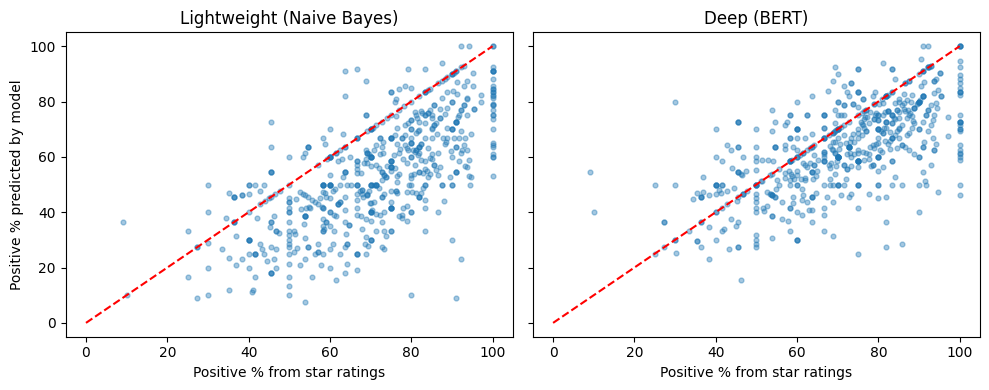

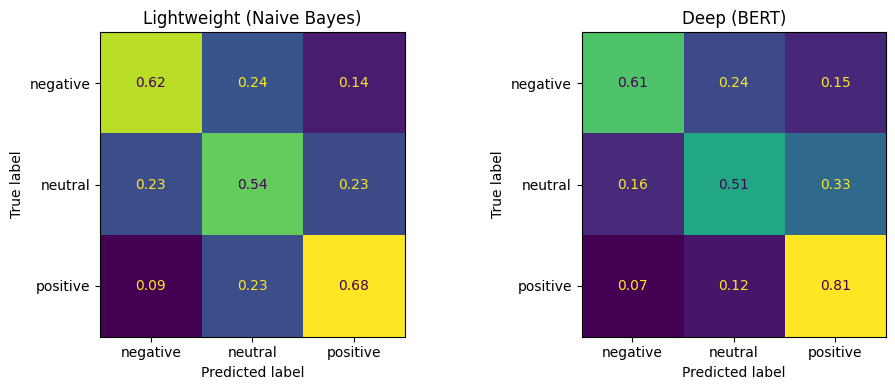

In [ ]:
if HAS_GPU:
    import matplotlib.pyplot as plt
    from sklearn.metrics import ConfusionMatrixDisplay

    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    for ax, (name, col) in zip(axes, [('Lightweight (Naive Bayes)', 'light_pos'), ('Deep (BERT)', 'deep_pos')]):
        ax.scatter(qualified['true_pos'], qualified[col], alpha=0.4, s=12)
        ax.plot([0, 100], [0, 100], 'r--')
        ax.set_title(name)
        ax.set_xlabel('Positive % from star ratings')
    axes[0].set_ylabel('Positive % predicted by model')
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/per_book_comparison.png', dpi=150)
    plt.show()

    labels = ['negative', 'neutral', 'positive']
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, (name, preds) in zip(axes, [('Lightweight (Naive Bayes)', lightweight_predictions), ('Deep (BERT)', deep_predictions)]):
        ConfusionMatrixDisplay.from_predictions(y_test, preds, labels=labels, normalize='true', ax=ax, colorbar=False, values_format='.2f')
        ax.set_title(name)
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/confusion_matrices.png', dpi=150)
    plt.show()

In [ ]:
# every number for the thesis is in one place
print(json.dumps(RESULTS, indent=2, default=_plain))
print()
print('Parts A-I done if no message above says otherwise. Download these four files from the Drive folder Book_Rec_Final and put them in the Streamlit app folder:')
print('  books_app.pkl   tfidf_app.joblib   book_sentiment.csv   similar_rules.py')

{
  "library_versions": {
    "python": "3.13.16",
    "scikit-learn": "1.6.1",
    "pandas": "2.2.3",
    "numpy": "2.1.3"
  },
  "raw_file_lines": {
    "books": 2360655,
    "authors": 829529,
    "reviews": 15739967
  },
  "books_file_lines_read": 2360655,
  "books_matching_before_dedup": 192667,
  "books_after_dedup": 33657,
  "review_sample_lines_read": 581963,
  "review_sample_books_covered": 25427,
  "review_sample_with_text": 199866,
  "sample_class_share": {
    "positive": 0.6826,
    "neutral": 0.1924,
    "negative": 0.1249
  },
  "train_reviews": 159892,
  "test_reviews": 39974,
  "unweighted_report": {
    "negative": {
      "precision": 0.8314720812182741,
      "recall": 0.16211401425178149,
      "f1-score": 0.2713268179559384,
      "support": 5052.0
    },
    "neutral": {
      "precision": 0.5016042780748663,
      "recall": 0.06088536933662209,
      "f1-score": 0.1085899513776337,
      "support": 7703.0
    },
    "positive": {
      "precision": 0.71028012823